# DSAN 6600 - 05_hubert_transfer.ipynb

Check-in 3 extension: **transfer learning from a self-supervised ECG foundation model** (HuBERT-ECG SMALL, Coppola et al.), compared against the Check-in 2 CNN on the same splits, labels, test sets and metrics.

| Regime | What trains | Model name |
|---|---|---|
| CNN from scratch (Check-in 2 baseline) | everything | `cnn_all` (loaded from saved predictions, not retrained) |
| **Frozen encoder** (linear probe) | new 5-class linear head only, on mean-pooled HuBERT embeddings | `hubert_frozen_all` |
| Frozen, pooled halves | same, but the two halves' embeddings are combined (mean + max) before the head | `hubert_frozen_meanmax2_all` |
| Frozen, pooled + overlap window | same, plus a 2.5-7.5 s window so nothing near the 5 s mark is split | `hubert_frozen_meanmax3_all` |
| **Fine-tuned encoder** | transformer layers + head (conv feature extractor stays frozen, as in the paper) | `hubert_finetuned_all` |

**Ablation:** frozen vs fine-tuned changes exactly one thing, whether the pretrained encoder weights update on PTB-XL. The pooled variants are two more one-change comparisons: `frozen` → `frozen_meanmax2` (how windows are combined), `frozen_meanmax2` → `frozen_meanmax3` (adding the overlapping window). Optional control (`RUN_SCRATCH = True`): the *same* HuBERT architecture trained from random init with the fine-tuned recipe, which separates "pretraining helps" from "a transformer helps".

**Default scope:** training group `all` only (folds 1-7, both sexes), 3 seeds, compared with `cnn_all`. Add `"female"`, `"male"` to `TRAIN_GROUPS` to run the full grid if there's time.

**Leakage caveat (must be reported):** HuBERT-ECG's 9.1M-ECG pretraining set includes PTB-XL with labels removed, and the paper doesn't say test folds were held out. The encoder has likely seen our test ECGs (never their labels or our sex split). Absolute AUROCs may be slightly optimistic; the male-female gap comparison is less affected because the exposure is the same for both sexes.

**Running on Colab (T4 GPU):** same setup as `03_cnn_baseline.ipynb`. Runtime → T4 GPU → Run all. Finished runs are backed up to `MyDrive/6600_project/backup/` and skipped on rerun. Rough T4 time: preprocessing ~3 min (first session only), frozen arm ~5 min total, fine-tuned arm ~1 min/epoch per run.

**Outputs** (same CSV format as the CNN, `EVAL.md`):
- `hubert_results/hubert_{regime}_{group}_seed{s}_preds.csv`, `_history.csv`, `hubert_config.json`
- `hubert_results/comparison_summary.csv`, `comparison_per_class.csv`, `comparison_miss_rates.csv`
- `figures/hubert_figures/*.png`

### Setup (Colab + paths)

In [ ]:
import os
import sys
import shutil
import subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/chloemjones13/6600_final_project.git"
REPO_DIR = "/content/6600_final_project"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/6600_project/"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR + "/notebooks")
    # The model's remote code was written for transformers 4.x
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40,<5", "wfdb"], check=True)
    CACHE_DIR = DRIVE_DIR
    BACKUP_DIR = DRIVE_DIR + "backup_hubert/"
else:
    CACHE_DIR = "../data/"
    BACKUP_DIR = None

PATH = "../data/"
SIGNAL_DIR = "../data/"
RESULTS_DIR = "../hubert_results/"
CNN_RESULTS_DIRS = ["../cnn_results/", "../results/"]      # where Check-in 2 CNN predictions may live
CKPT_DIR = "../checkpoints/"
FIG_DIR = "../figures/hubert_figures/"
for d in [RESULTS_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR] + ([BACKUP_DIR] if BACKUP_DIR else []):
    os.makedirs(d, exist_ok=True)

if not os.path.exists(PATH + "ptbxl_model.pkl"):
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "--output", "/tmp/01_executed.ipynb", "01_data_cleaning.ipynb"], check=True)
assert os.path.exists(PATH + "ptbxl_model.pkl"), "01_data_cleaning.ipynb didn't create ptbxl_model.pkl"
print("Colab:", IN_COLAB, "| working dir:", os.getcwd())

Mounted at /content/drive
Colab: True | working dir: /content/6600_final_project/notebooks


In [ ]:
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import torch
import torch.nn as nn
from scipy.signal import firwin, filtfilt, resample, decimate
from sklearn.metrics import roc_auc_score, average_precision_score
from transformers import AutoConfig, AutoModel

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
Y_COLS = ["y_" + c for c in CLASSES]
P_COLS = ["p_" + c for c in CLASSES]

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "| mixed precision:", USE_AMP)
if IN_COLAB and DEVICE.type != "cuda":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then Run all again.")


def save_fig(name):
    plt.savefig(f"{FIG_DIR}{name}.png", dpi=150, bbox_inches="tight")
    if BACKUP_DIR:
        os.makedirs(BACKUP_DIR + "figures", exist_ok=True)
        shutil.copy(f"{FIG_DIR}{name}.png", BACKUP_DIR + "figures/")

Device: cuda | mixed precision: True


In [ ]:
CONFIG = dict(
    pretrained_model="Edoardo-Coppola/hubert-ecg-small",   # safetensors weights + small remote-code file
    license="CC BY-NC 4.0 (non-commercial)",
    # same evaluation protocol as the CNN
    train_folds=[1, 2, 3, 4, 5, 6, 7], val_folds=[8], test_folds=[9, 10],
    seeds=[0, 1, 2],
    selection_metric="validation macro AUROC",
    loss="BCEWithLogitsLoss (unweighted, same as CNN)",
    scheduler="ReduceLROnPlateau(mode=max on val macro AUROC, factor=0.5, patience=2)",
    # input pipeline = the authors' preprocessing (see the preprocessing section)
    input="12 leads, bandpass 0.05-47 Hz (FIR), resample 100->500 Hz, per-lead min-max to [-1, 1], "
          "two 5 s halves, each flattened (12 x 2500) and decimated x5 -> 6000 samples",
    train_crop="one random half per record per batch",
    eval_crop="mean of sigmoid probabilities over both halves",
    # frozen encoder = linear probe on mean-pooled final-layer embeddings
    frozen=dict(lr=1e-3, weight_decay=1e-4, batch_size=64, max_epochs=60, patience=7, head_dropout=0.2),
    # fine-tuned encoder: paper recipe (lr 1e-5, AdamW betas (0.9, 0.98), wd 0.01, conv extractor frozen,
    # layerdrop 0, dropout 0); head gets a larger lr because it starts from random init
    finetuned=dict(lr_backbone=1e-5, lr_head=1e-3, weight_decay=0.01, batch_size=64,
                   max_epochs=20, patience=5, head_dropout=0.1, grad_clip=1.0),
)
# Frozen-encoder variants that pool window embeddings (mean + max) before the linear head.
# Window starts are in 500 Hz samples: 0 = 0-5 s, 1250 = 2.5-7.5 s (overlap), 2500 = 5-10 s.
POOLED_PROBES = {
    "frozen_meanmax2": [0, 2500],          # the two halves (isolates the pooling change)
    "frozen_meanmax3": [0, 1250, 2500],    # + overlapping middle window (isolates the extra window)
}
CONFIG["pooled_probes"] = dict(windows_500hz_starts=POOLED_PROBES, pooling="concat(mean, max) over windows",
                               head="same linear probe and hyperparameters as `frozen`")

TRAIN_GROUPS = ["all"]          # add "female", "male" for the full 3 x 2 grid
FINETUNE_REGIMES = ["finetuned"]
RUN_SCRATCH = False             # True = also train HuBERT from random init (pretraining control, ~1 h on a T4)
if RUN_SCRATCH:
    FINETUNE_REGIMES.append("scratch")
REGIMES = ["frozen"] + list(POOLED_PROBES) + FINETUNE_REGIMES
CONFIG["train_groups"], CONFIG["regimes"] = TRAIN_GROUPS, REGIMES

### Load the cleaned data and define splits

Identical to `03_cnn_baseline.ipynb`, so the test records and labels match the CNN's exactly (checked against the saved CNN predictions further down).

In [ ]:
df = pd.read_pickle(PATH + "ptbxl_model.pkl")
assert (df[CLASSES].sum(axis=1) > 0).all(), "Run the last cell of 01_data_cleaning.ipynb first"
df["split"] = np.where(df["strat_fold"] <= 7, "train", np.where(df["strat_fold"] == 8, "val", "test"))
print(pd.crosstab(df["split"], df["sex_label"]))

sex_label  female  male
split                  
test         1842  2137
train        6566  7444
val           942  1061


In [ ]:
RAW_CACHE = CACHE_DIR + "X_100hz.npy"          # same cache the CNN notebook builds
RAW_CACHE_IDS = CACHE_DIR + "X_100hz_ids.npy"


def load_raw_signals(df):
    # (N, 12, 1000) raw 100 Hz signals in mV, from the CNN cache if present
    if os.path.exists(RAW_CACHE) and np.array_equal(np.load(RAW_CACHE_IDS), df.index.values):
        return np.load(RAW_CACHE)
    signal_dir = SIGNAL_DIR
    if IN_COLAB:
        if not os.path.exists("/content/ptbxl/records100"):
            subprocess.run(["unzip", "-q", DRIVE_DIR + "records100.zip", "-d", "/content/ptbxl"], check=True)
        signal_dir = "/content/ptbxl/"
    X = np.empty((len(df), 12, 1000), dtype=np.float32)
    for i, fn in enumerate(df["filename_lr"]):
        X[i] = wfdb.rdsamp(signal_dir + fn)[0].T
        if i % 2000 == 0:
            print(f"{i}/{len(df)}")
    np.save(RAW_CACHE, X)
    np.save(RAW_CACHE_IDS, df.index.values)
    return X

### Preprocessing: match what the encoder was pretrained on

A pretrained encoder expects inputs that look like its pretraining data, so this follows the authors' code (`hubert_ecg/utils.py::ecg_preprocessing` and `dataset.py`) rather than the CNN's per-lead z-score:

1. FIR bandpass 0.05-47 Hz, zero-phase (`filtfilt`), order `int(0.3 * fs)`; the same filter biosppy builds in their code, re-implemented with scipy so no extra install is needed.
2. Resample 100 → 500 Hz.
3. Per-lead min-max scaling to [-1, 1] (over the whole 10 s record).
4. Cut into two 5 s halves (12 × 2500 each), flatten lead by lead, decimate ×5 → 6,000 samples per half.

This is per-record, so it uses no statistics from other records (no train/test leakage, and no male/female statistics shared across groups).

Skipping the 100 → 500 → 100 Hz round trip is *not* equivalent (it changes the signal by up to ~0.14 on the [-1, 1] scale because of the decimation filter), so the full pipeline runs once and is cached (~1 GB).

In [ ]:
def bandpass_fir(x, fs=100, band=(0.05, 47.0)):
    # Same FIR design as biosppy.filter_signal(ftype="FIR", band="bandpass", order=int(0.3*fs))
    order = int(0.3 * fs)
    order += order % 2 == 0                  # biosppy forces an odd number of taps
    b = firwin(order, [band[0] / (fs / 2), band[1] / (fs / 2)], pass_zero=False)
    return filtfilt(b, [1.0], x, axis=-1)


def minmax_scale(x, eps=1e-8):
    # Per-lead min-max to [-1, 1]
    lo, hi = x.min(axis=1, keepdims=True), x.max(axis=1, keepdims=True)
    return 2 * (x - lo) / (hi - lo + eps) - 1


HALVES = (0, 2500)      # window starts in 500 Hz samples: 0-5 s and 5-10 s
MIDDLE = (1250,)        # 2.5-7.5 s, overlaps both halves (used by the pooled probe later)


def to_hubert_windows(x_100hz, starts=HALVES):
    # One record (12, 1000) at 100 Hz -> (len(starts), 6000): 5 s windows in the encoder's input format
    x = minmax_scale(resample(bandpass_fir(x_100hz, fs=100), 5000, axis=1))
    return np.stack([decimate(x[:, s:s + 2500].reshape(-1), 5) for s in starts]).astype(np.float32)


def load_hubert_inputs(df, starts=HALVES, name="X_hubert_halves"):
    # Preprocess every record once and cache to Drive as {name}.npy
    cache, cache_ids = f"{CACHE_DIR}{name}.npy", f"{CACHE_DIR}{name}_ids.npy"
    if os.path.exists(cache) and np.array_equal(np.load(cache_ids), df.index.values):
        return np.load(cache)
    raw = load_raw_signals(df)
    assert np.isfinite(raw).all()
    out = np.empty((len(raw), len(starts), 6000), dtype=np.float32)
    t0 = time.time()
    for i in range(len(raw)):
        out[i] = to_hubert_windows(raw[i].astype(np.float64), starts)
        if i % 2000 == 0:
            print(f"{i}/{len(raw)} ({time.time() - t0:.0f}s)")
    np.save(cache, out)
    np.save(cache_ids, df.index.values)
    return out


X = load_hubert_inputs(df)
print(X.shape, "| range", float(X.min()), float(X.max()))
assert X.shape[1:] == (2, 6000) and np.isfinite(X).all()

(19992, 2, 6000) | range -1.1912713050842285 1.1907387971878052


In [ ]:
# Split by fold; train/val get filtered to each model's group later, test always keeps both sexes
SPLITS = ["train", "val", "test"]
masks = {s: (df["split"] == s).values for s in SPLITS}
Xs = {s: X[masks[s]] for s in SPLITS}
Ys = {s: df.loc[masks[s], CLASSES].values.astype(np.float32) for s in SPLITS}
meta = {s: df[masks[s]] for s in SPLITS}
del X


def group_mask(split, group):
    sex = meta[split]["sex"].values
    if group == "all":
        return np.ones(len(sex), bool)
    return sex == (1 if group == "female" else 0)


for g in TRAIN_GROUPS:
    print(f"{g:6s} train {group_mask('train', g).sum():6d} | val {group_mask('val', g).sum():5d}")

all    train  14010 | val  2003


### Model

`load_backbone()` loads the pretrained encoder. The Hub version runs the stock Hugging Face `HubertModel.forward`, which applies its pretraining masking (`mask_time_prob = 0.33`) and layerdrop whenever the model is in training mode. Both are switched off here; otherwise fine-tuning would randomly mask a third of every ECG. Dropout inside the encoder is set to 0, as in the paper's fine-tuning scripts.

The classifier mean-pools the final-layer frame embeddings (≈93 frames × 512) and applies dropout + a linear layer → 5 logits, the same head as `HuBERTECGForClassification`.

A warning that `masked_spec_embed` was "not used" is expected: that's the learned mask token, which only exists when masking is on.

In [ ]:
BACKBONE_OVERRIDES = dict(mask_time_prob=0.0, mask_feature_prob=0.0, layerdrop=0.0,
                          hidden_dropout=0.0, attention_dropout=0.0, activation_dropout=0.0,
                          feat_proj_dropout=0.0)


def load_backbone(pretrained=True):
    if pretrained:
        return AutoModel.from_pretrained(CONFIG["pretrained_model"], trust_remote_code=True,
                                         use_safetensors=True, **BACKBONE_OVERRIDES)
    cfg = AutoConfig.from_pretrained(CONFIG["pretrained_model"], trust_remote_code=True, **BACKBONE_OVERRIDES)
    return AutoModel.from_config(cfg, trust_remote_code=True)       # same architecture, random weights


def freeze_conv_extractor(backbone):
    fe = backbone.feature_extractor
    if hasattr(fe, "_freeze_parameters"):
        fe._freeze_parameters()              # also skips the input-gradient trick in HF's feature encoder
    else:
        fe.requires_grad_(False)


def embed(backbone, x):
    # (B, 6000) -> (B, hidden) mean-pooled final-layer embeddings
    return backbone(x).last_hidden_state.mean(dim=1)


class HuBERTClassifier(nn.Module):
    def __init__(self, backbone, n_classes=len(CLASSES), dropout=0.1):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(backbone.config.hidden_size, n_classes)

    def forward(self, x):
        return self.head(self.dropout(embed(self.backbone, x)))


def linear_probe(hidden_size, n_classes=len(CLASSES), dropout=0.2):
    return nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_size, n_classes))


_bb = load_backbone()
print(type(_bb).__name__, "| encoder parameters:", sum(p.numel() for p in _bb.parameters()))
assert _bb.config.mask_time_prob == 0.0 and _bb.config.layerdrop == 0.0, "masking overrides didn't apply"
with torch.no_grad():
    print("Embedding shape:", embed(_bb.eval(), torch.from_numpy(Xs["train"][:2, 0])).shape)   # expect (2, 512)
HIDDEN = _bb.config.hidden_size
del _bb

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

hubert_ecg.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/Edoardo-Coppola/hubert-ecg-small:
- hubert_ecg.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/122M [00:00<?, ?B/s]

Some weights of the model checkpoint at Edoardo-Coppola/hubert-ecg-small were not used when initializing HuBERTECG: ['masked_spec_embed']
- This IS expected if you are initializing HuBERTECG from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing HuBERTECG from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


HuBERTECG | encoder parameters: 30468480
Embedding shape: torch.Size([2, 512])


### Training functions

One training loop serves all regimes. Every model maps a `(batch, features)` tensor to 5 logits; the data arrays are `(records, 2 halves, features)`, so training draws one random half per record (the paper's random-crop augmentation) and evaluation averages probabilities over both halves. Checkpoint selection, LR schedule and early stopping follow the CNN: best validation macro AUROC.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def batches(n, batch_size, shuffle, rng=None):
    idx = rng.permutation(n) if shuffle else np.arange(n)
    for i in range(0, n, batch_size):
        yield idx[i:i + batch_size]


def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)


@torch.no_grad()
def predict_halves(model, X, batch_size=128):
    # Mean sigmoid probability over the views; X is (N, views, F): 2 halves, or 1 pooled vector
    model.eval()
    n_views = X.shape[1]
    out = []
    for b in batches(len(X), batch_size, shuffle=False):
        xb = torch.from_numpy(X[b]).to(DEVICE)
        with autocast():
            p = sum(torch.sigmoid(model(xb[:, h]).float()) for h in range(n_views)) / n_views
        out.append(p.cpu().numpy())
    return np.concatenate(out)


def bce(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def fit(model, param_groups, data, hp, seed, ckpt, name):
    # Train with random-half augmentation; keep the best-validation-AUROC weights
    X_tr, Y_tr, X_va, Y_va = data
    rng = np.random.default_rng(seed)
    opt = torch.optim.AdamW(param_groups, betas=(0.9, 0.98), weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = nn.BCEWithLogitsLoss()
    trainable = [p for g in param_groups for p in g["params"]]
    best, bad, hist = -1.0, 0, []
    for epoch in range(1, hp["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        total = 0.0
        for b in batches(len(X_tr), hp["batch_size"], shuffle=True, rng=rng):
            half = rng.integers(0, X_tr.shape[1], len(b))      # random view per record (always 0 if pooled)
            xb = torch.from_numpy(X_tr[b, half]).to(DEVICE)
            yb = torch.from_numpy(Y_tr[b]).to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with autocast():
                loss = loss_fn(model(xb).float(), yb)
            scaler.scale(loss).backward()
            if hp.get("grad_clip"):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(trainable, hp["grad_clip"])
            scaler.step(opt)
            scaler.update()
            total += loss.item() * len(b)

        p_val = predict_halves(model, X_va)
        val_auc = roc_auc_score(Y_va, p_val, average="macro")
        sched.step(val_auc)
        hist.append(dict(epoch=epoch, train_loss=total / len(X_tr), val_loss=bce(Y_va, p_val),
                         val_auroc=val_auc, lr=opt.param_groups[-1]["lr"], sec=time.time() - t0))
        h = hist[-1]
        print(f"{name} | epoch {epoch:2d} | train {h['train_loss']:.4f} | val loss {h['val_loss']:.4f} "
              f"| val AUROC {val_auc:.4f} | {h['sec']:.0f}s")
        if val_auc > best:
            best, bad = val_auc, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= hp["patience"]:
                print(f"Early stop at epoch {epoch}; best val AUROC {best:.4f}")
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    hist = pd.DataFrame(hist)
    hist["n_train"] = len(X_tr)
    return model, hist


def group_data(feats, group):
    # (train X, train Y, val X, val Y) for one training group; feats maps split -> (N, 2, F)
    tr, va = group_mask("train", group), group_mask("val", group)
    return feats["train"][tr], Ys["train"][tr], feats["val"][va], Ys["val"][va]

In [ ]:
def save_preds(model, feats, run_name, group, seed, n_train):
    # Validation + test predictions (both sexes) in the same format as the CNN
    parts = []
    for s in ["val", "test"]:
        p = predict_halves(model, feats[s])
        m = meta[s]
        out = pd.DataFrame({
            "ecg_id": m.index.values, "split": s, "sex": m["sex"].values, "age": m["age"].values,
            "age_band": m["age_band"].astype(str).values, "device": m["device"].values,
            "validated_by_human": m["validated_by_human"].values,
        })
        for j, c in enumerate(CLASSES):
            out["y_" + c] = Ys[s][:, j].astype(int)
        for j, c in enumerate(CLASSES):
            out["p_" + c] = p[:, j]
        out["model"], out["train_group"], out["n_train"], out["seed"] = run_name.rsplit("_seed", 1)[0], group, n_train, seed
        parts.append(out)
    pd.concat(parts).to_csv(f"{RESULTS_DIR}{run_name}_preds.csv", index=False)


def run_files(run_name):
    return [f"{RESULTS_DIR}{run_name}_preds.csv", f"{RESULTS_DIR}{run_name}_history.csv"]


def backup(run_name):
    if BACKUP_DIR:
        for f in run_files(run_name):
            shutil.copy(f, BACKUP_DIR)


def restore(run_name):
    # True if this run already finished (locally or in the Drive backup)
    for f in run_files(run_name):
        b = BACKUP_DIR + os.path.basename(f) if BACKUP_DIR else None
        if not os.path.exists(f) and b and os.path.exists(b):
            shutil.copy(b, f)
    return all(os.path.exists(f) for f in run_files(run_name))

### Arm 1: frozen encoder (linear probe)

The encoder never updates, so its embeddings are computed once for every record and both halves (cached to Drive, ~90 MB) and only the linear head trains. The frozen encoder never sees our labels or our sex split, so any male-female gap here comes from the pretrained representation plus a linear read-out.

In [ ]:
EMB_CACHE = CACHE_DIR + "hubert_small_embeddings.npz"


@torch.no_grad()
def extract_embeddings(backbone, X, batch_size=128):
    # (N, windows, 6000) -> (N, windows, hidden)
    backbone.eval()
    out = np.empty((len(X), X.shape[1], backbone.config.hidden_size), dtype=np.float32)
    for b in batches(len(X), batch_size, shuffle=False):
        xb = torch.from_numpy(X[b]).to(DEVICE)
        with autocast():
            for h in range(X.shape[1]):
                out[b, h] = embed(backbone, xb[:, h]).float().cpu().numpy()
    return out


def load_embeddings(inputs, cache):
    # Frozen-encoder embeddings for every split, cached to Drive; inputs maps split -> (N, windows, 6000)
    if os.path.exists(cache):
        z = np.load(cache)
        if all(np.array_equal(z[f"ids_{s}"], meta[s].index.values) for s in SPLITS):
            return {s: z[s] for s in SPLITS}
    backbone = load_backbone().to(DEVICE)
    emb = {}
    for s in SPLITS:
        t0 = time.time()
        emb[s] = extract_embeddings(backbone, inputs[s])
        print(f"{s}: {emb[s].shape} in {time.time() - t0:.0f}s")
    np.savez(cache, **emb, **{f"ids_{s}": meta[s].index.values for s in SPLITS})
    del backbone
    torch.cuda.empty_cache()
    return emb


EMB = load_embeddings(Xs, EMB_CACHE)
assert all(np.isfinite(EMB[s]).all() for s in SPLITS)

In [ ]:
def train_frozen(group, seed):
    hp = CONFIG["frozen"]
    set_seed(seed)
    model = linear_probe(HIDDEN, dropout=hp["head_dropout"]).to(DEVICE)
    groups = [{"params": list(model.parameters()), "lr": hp["lr"]}]
    name = f"hubert_frozen_{group}_seed{seed}"
    return fit(model, groups, group_data(EMB, group), hp, seed, f"{CKPT_DIR}{name}.pt", name)


histories = {}
for group in TRAIN_GROUPS:
    for seed in CONFIG["seeds"]:
        run = f"hubert_frozen_{group}_seed{seed}"
        if restore(run):
            print(f"{run}: already done, skipping")
        else:
            model, hist = train_frozen(group, seed)
            hist.to_csv(run_files(run)[1], index=False)
            save_preds(model, EMB, run, group, seed, int(hist["n_train"].iloc[0]))
            backup(run)
        histories[run] = pd.read_csv(run_files(run)[1])

hubert_frozen_all_seed0: already done, skipping
hubert_frozen_all_seed1: already done, skipping
hubert_frozen_all_seed2: already done, skipping


### Arm 1b: frozen encoder, pooled over overlapping windows

The `frozen` arm predicts each 5 s half separately and averages the two probabilities, so an abnormality that only shows up in one half gets diluted, and one that straddles the 5 s mark (e.g. seconds 4-6) is split across both halves and never seen whole.

These variants pool the window **embeddings** instead and let the linear head learn how to combine them:
- Features per record = [mean over windows, max over windows] of the 512-d embeddings → 1,024 numbers. Max keeps a strong finding from any one window; mean keeps what's consistent. The result doesn't depend on window order.
- `frozen_meanmax2`: the two halves (0-5 s, 5-10 s). Compared with `frozen`, only the combining method changes.
- `frozen_meanmax3`: adds an overlapping middle window (2.5-7.5 s), so seconds 4-6 sit fully inside one window. Compared with `frozen_meanmax2`, only the extra window changes.

Only the middle window is new: it's preprocessed and embedded once (cached to Drive, a few minutes on a T4); the halves reuse the caches above. Same head, optimizer, early stopping and hyperparameters as `frozen`.

In [ ]:
# Middle window (2.5-7.5 s): preprocess + embed once, then line up all three windows by start time
X_mid = load_hubert_inputs(df, starts=MIDDLE, name="X_hubert_middle")
Xs_mid = {s: X_mid[masks[s]] for s in SPLITS}
del X_mid
EMB_MID = load_embeddings(Xs_mid, CACHE_DIR + "hubert_small_embeddings_middle.npz")
del Xs_mid
WINDOW_EMB = {s: {0: EMB[s][:, 0], 1250: EMB_MID[s][:, 0], 2500: EMB[s][:, 1]} for s in SPLITS}
print({w: e.shape for w, e in WINDOW_EMB["train"].items()})

0/19992 (0s)
2000/19992 (23s)
4000/19992 (38s)
6000/19992 (50s)
8000/19992 (62s)
10000/19992 (73s)
12000/19992 (85s)
14000/19992 (97s)
16000/19992 (109s)
18000/19992 (120s)


Some weights of the model checkpoint at Edoardo-Coppola/hubert-ecg-small were not used when initializing HuBERTECG: ['masked_spec_embed']
- This IS expected if you are initializing HuBERTECG from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing HuBERTECG from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


train: (14010, 1, 512) in 11s
val: (2003, 1, 512) in 1s
test: (3979, 1, 512) in 3s
{0: (14010, 512), 1250: (14010, 512), 2500: (14010, 512)}


In [ ]:
def pool_windows(split, starts):
    # (N, 1, 2 * hidden): concat(mean, max) over the chosen windows' embeddings; one "view" per record
    e = np.stack([WINDOW_EMB[split][w] for w in starts], axis=1)
    return np.concatenate([e.mean(axis=1), e.max(axis=1)], axis=1)[:, None, :]


def train_pooled(regime, feats, group, seed):
    hp = CONFIG["frozen"]
    set_seed(seed)
    model = linear_probe(2 * HIDDEN, dropout=hp["head_dropout"]).to(DEVICE)
    groups = [{"params": list(model.parameters()), "lr": hp["lr"]}]
    name = f"hubert_{regime}_{group}_seed{seed}"
    return fit(model, groups, group_data(feats, group), hp, seed, f"{CKPT_DIR}{name}.pt", name)


for regime, starts in POOLED_PROBES.items():
    feats = {s: pool_windows(s, starts) for s in SPLITS}
    for group in TRAIN_GROUPS:
        for seed in CONFIG["seeds"]:
            run = f"hubert_{regime}_{group}_seed{seed}"
            if restore(run):
                print(f"{run}: already done, skipping")
            else:
                model, hist = train_pooled(regime, feats, group, seed)
                hist.to_csv(run_files(run)[1], index=False)
                save_preds(model, feats, run, group, seed, int(hist["n_train"].iloc[0]))
                backup(run)
            histories[run] = pd.read_csv(run_files(run)[1])

hubert_frozen_meanmax2_all_seed0 | epoch  1 | train 0.4162 | val loss 0.3714 | val AUROC 0.8495 | 1s
hubert_frozen_meanmax2_all_seed0 | epoch  2 | train 0.3690 | val loss 0.3588 | val AUROC 0.8591 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  3 | train 0.3605 | val loss 0.3501 | val AUROC 0.8643 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  4 | train 0.3553 | val loss 0.3483 | val AUROC 0.8670 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  5 | train 0.3519 | val loss 0.3433 | val AUROC 0.8698 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  6 | train 0.3494 | val loss 0.3420 | val AUROC 0.8719 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  7 | train 0.3472 | val loss 0.3385 | val AUROC 0.8725 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  8 | train 0.3469 | val loss 0.3375 | val AUROC 0.8741 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch  9 | train 0.3451 | val loss 0.3373 | val AUROC 0.8736 | 0s
hubert_frozen_meanmax2_all_seed0 | epoch 10 | train 0.3453 | val loss 0.3357 | val AUROC 0.

### Arm 2: fine-tuned encoder

Paper recipe for PTB-XL (`scripts/finetune.sh`): all 8 transformer blocks trainable, convolutional feature extractor frozen, AdamW (betas 0.9/0.98, weight decay 0.01), encoder LR 1e-5, layerdrop and dropout off. Two deliberate differences: the randomly initialized head gets LR 1e-3 (so it isn't stuck at 1e-5 while the encoder adapts), and the loss is **unweighted** like the CNN (the paper uses positive-class weights, which would make the calibration-by-sex comparison unfair).

Training budget: max 20 epochs, early stop after 5 without validation improvement (the CNN used 40/7; the transformer is ~25× larger, so the budget is cut for Colab time). If `RUN_SCRATCH` is on, the same loop also trains the identical architecture from random weights.

In [ ]:
def build_finetune_model(pretrained, seed):
    hp = CONFIG["finetuned"]
    set_seed(seed)                       # seeds the head init (and the backbone init for scratch)
    model = HuBERTClassifier(load_backbone(pretrained=pretrained), dropout=hp["head_dropout"])
    freeze_conv_extractor(model.backbone)
    model = model.to(DEVICE)
    backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{"params": backbone_params, "lr": hp["lr_backbone"]},
              {"params": list(model.head.parameters()), "lr": hp["lr_head"]}]
    return model, groups


def train_finetune(regime, group, seed):
    model, groups = build_finetune_model(pretrained=(regime == "finetuned"), seed=seed)
    n_train = sum(p.numel() for g in groups for p in g["params"])
    name = f"hubert_{regime}_{group}_seed{seed}"
    print(f"--- {name}: {n_train:,} trainable parameters")
    model, hist = fit(model, groups, group_data(Xs, group), CONFIG["finetuned"], seed, f"{CKPT_DIR}{name}.pt", name)
    return model, hist


for regime in FINETUNE_REGIMES:
    for group in TRAIN_GROUPS:
        for seed in CONFIG["seeds"]:
            run = f"hubert_{regime}_{group}_seed{seed}"
            if restore(run):
                print(f"{run}: already done, skipping")
            else:
                model, hist = train_finetune(regime, group, seed)
                hist.to_csv(run_files(run)[1], index=False)
                save_preds(model, Xs, run, group, seed, int(hist["n_train"].iloc[0]))
                backup(run)
                del model
                torch.cuda.empty_cache()
            histories[run] = pd.read_csv(run_files(run)[1])

with open(RESULTS_DIR + "hubert_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
if BACKUP_DIR:
    shutil.copy(RESULTS_DIR + "hubert_config.json", BACKUP_DIR)

hubert_finetuned_all_seed0: already done, skipping
hubert_finetuned_all_seed1: already done, skipping
hubert_finetuned_all_seed2: already done, skipping


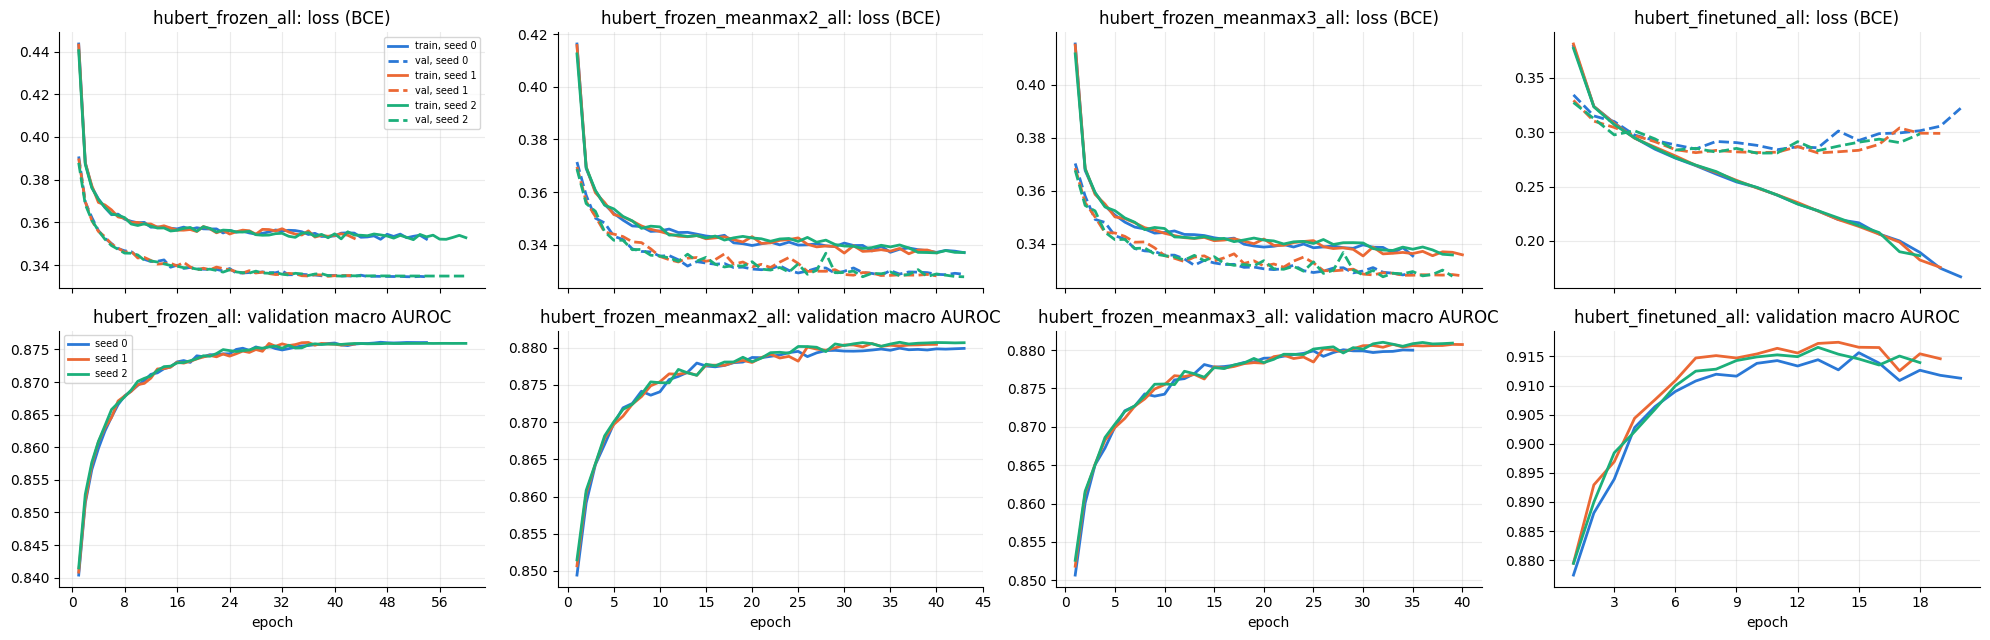

In [ ]:
# Training curves: one column per regime, one color per seed (solid = train, dashed = validation)
from matplotlib.ticker import MaxNLocator

SEED_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
g0 = TRAIN_GROUPS[0]
fig, axes = plt.subplots(2, len(REGIMES), figsize=(5 * len(REGIMES), 6.5), sharex="col", squeeze=False)
for j, r in enumerate(REGIMES):
    for k, seed in enumerate(CONFIG["seeds"]):
        h, col = histories[f"hubert_{r}_{g0}_seed{seed}"], SEED_COLORS[k % 3]
        axes[0, j].plot(h["epoch"], h["train_loss"], color=col, lw=2, label=f"train, seed {seed}")
        axes[0, j].plot(h["epoch"], h["val_loss"], "--", color=col, lw=2, label=f"val, seed {seed}")
        axes[1, j].plot(h["epoch"], h["val_auroc"], color=col, lw=2, label=f"seed {seed}")
    axes[0, j].set_title(f"hubert_{r}_{g0}: loss (BCE)")
    axes[1, j].set_title(f"hubert_{r}_{g0}: validation macro AUROC")
    axes[1, j].set_xlabel("epoch")
    axes[1, j].xaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in axes[:, j]:
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(fontsize=7)
axes[1, 0].legend(fontsize=7)
plt.tight_layout()
save_fig("hubert_training_curves")
plt.show()

## Comparison with the Check-in 2 CNN

Same test records (folds 9-10, 2,137 male / 1,842 female), same labels, same metrics, 3 seeds each. The CNN numbers come from its saved prediction files, so nothing about the baseline changes.

In [ ]:
def find_cnn_preds(group, seed):
    for d in CNN_RESULTS_DIRS:
        f = f"{d}cnn_{group}_seed{seed}_preds.csv"
        if os.path.exists(f):
            return pd.read_csv(f)
    raise FileNotFoundError(f"cnn_{group}_seed{seed}_preds.csv not found in {CNN_RESULTS_DIRS}")


preds = {}
for group in TRAIN_GROUPS:
    for seed in CONFIG["seeds"]:
        preds[(f"cnn_{group}", seed)] = find_cnn_preds(group, seed)
        for r in REGIMES:
            preds[(f"hubert_{r}_{group}", seed)] = pd.read_csv(f"{RESULTS_DIR}hubert_{r}_{group}_seed{seed}_preds.csv")

# Same-protocol check: every model is scored on exactly the same test records with the same labels
ref = preds[(f"cnn_{TRAIN_GROUPS[0]}", 0)].query("split == 'test'").set_index("ecg_id")[Y_COLS + ["sex"]].sort_index()
for key, p in preds.items():
    t = p.query("split == 'test'").set_index("ecg_id")[Y_COLS + ["sex"]].sort_index()
    assert t.equals(ref), f"{key}: test records/labels differ from the CNN's"
print("All models share the same", len(ref), "test records and labels.")
MODEL_ORDER = list(dict.fromkeys(k[0] for k in preds))

All models share the same 3979 test records and labels.


In [ ]:
def summarize(p):
    t = p[p["split"] == "test"]
    r = {}
    for name, mask in [("all", np.ones(len(t), bool)), ("male", (t["sex"] == 0).values), ("female", (t["sex"] == 1).values)]:
        y, s = t.loc[mask, Y_COLS].values, t.loc[mask, P_COLS].values
        r[f"auroc_{name}"] = roc_auc_score(y, s, average="macro")
        r[f"auprc_{name}"] = average_precision_score(y, s, average="macro")
    r["gap_auroc (M-F)"] = r["auroc_male"] - r["auroc_female"]
    return r


res = pd.DataFrame([dict(model=m, seed=s, **summarize(p)) for (m, s), p in preds.items()])
summary = res.drop(columns="seed").groupby("model", sort=False).agg(["mean", "std"])
summary.to_csv(RESULTS_DIR + "comparison_summary.csv")
summary.round(3)

auroc_all        auprc_all        auroc_male  \
                                mean    std      mean    std       mean   
model                                                                     
cnn_all                        0.924  0.003     0.813  0.004      0.930   
hubert_frozen_all              0.863  0.000     0.685  0.000      0.863   
hubert_frozen_meanmax2_all     0.867  0.000     0.692  0.000      0.867   
hubert_frozen_meanmax3_all     0.868  0.001     0.695  0.001      0.869   
hubert_finetuned_all           0.902  0.001     0.758  0.003      0.903   

                                  auprc_male        auroc_female         \
                              std       mean    std         mean    std   
model                                                                     
cnn_all                     0.003      0.823  0.003        0.917  0.003   
hubert_frozen_all           0.000      0.692  0.000        0.862  0.000   
hubert_frozen_meanmax2_all  0.000      0.699  0.000        0.866  0.000   
hubert_frozen_meanmax3_all  0.001      0.704  0.001        0.865  0.001   
hubert_finetuned_all        0.001      0.764  0.002        0.902  0.002   

                           auprc_female        gap_auroc (M-F)         
                                   mean    std            mean    std  
model                                                                  
cnn_all                           0.801  0.006           0.012  0.001  
hubert_frozen_all                 0.675  0.000           0.001  0.000  
hubert_frozen_meanmax2_all        0.681  0.000           0.001  0.000  
hubert_frozen_meanmax3_all        0.682  0.001           0.004  0.000  
hubert_finetuned_all              0.748  0.003           0.002  0.002

In [ ]:
# Headline table: macro AUROC by test sex + gap, and the change vs the CNN (mean over seeds)
cols = ["auroc_male", "auroc_female", "gap_auroc (M-F)", "auprc_female"]
head = summary.xs("mean", axis=1, level=1)[cols].copy()
for group in TRAIN_GROUPS:
    base = head.loc[f"cnn_{group}"]
    for m in head.index:
        if m.endswith(f"_{group}"):
            for c in ["auroc_female", "gap_auroc (M-F)"]:
                head.loc[m, f"Δ {c} vs cnn"] = head.loc[m, c] - base[c]
head.round(3)

,auroc_male,auroc_female,gap_auroc (M-F),auprc_female,Δ auroc_female vs cnn,Δ gap_auroc (M-F) vs cnn
model,,,,,,
cnn_all,0.930,0.917,0.012,0.801,0.000,0.000
hubert_frozen_all,0.863,0.862,0.001,0.675,-0.056,-0.011
hubert_frozen_meanmax2_all,0.867,0.866,0.001,0.681,-0.051,-0.011
hubert_frozen_meanmax3_all,0.869,0.865,0.004,0.682,-0.052,-0.008
hubert_finetuned_all,0.903,0.902,0.002,0.748,-0.016,-0.011


In [ ]:
# Per-class AUROC by test sex and the male-female gap (mean over seeds)
rows = []
for (m, s), p in preds.items():
    t = p[p["split"] == "test"]
    for sex, name in [(0, "male"), (1, "female")]:
        tt = t[t["sex"] == sex]
        for c in CLASSES:
            rows.append(dict(model=m, cls=c, test=name, auroc=roc_auc_score(tt["y_" + c], tt["p_" + c])))
per_class = (pd.DataFrame(rows).groupby(["model", "cls", "test"], sort=False)["auroc"].mean()
             .unstack()[["male", "female"]])
per_class["gap (M-F)"] = per_class["male"] - per_class["female"]
per_class.to_csv(RESULTS_DIR + "comparison_per_class.csv")
per_class.round(3)

test                              male  female  gap (M-F)
model                      cls                           
cnn_all                    NORM  0.947   0.940      0.007
                           MI    0.931   0.911      0.021
                           STTC  0.939   0.926      0.012
                           CD    0.929   0.914      0.015
                           HYP   0.902   0.895      0.007
hubert_frozen_all          NORM  0.904   0.904     -0.001
                           MI    0.876   0.852      0.024
                           STTC  0.896   0.903     -0.007
                           CD    0.859   0.849      0.010
                           HYP   0.780   0.800     -0.020
hubert_frozen_meanmax2_all NORM  0.905   0.906     -0.001
                           MI    0.878   0.856      0.022
                           STTC  0.901   0.905     -0.003
                           CD    0.867   0.856      0.011
                           HYP   0.783   0.807     -0.024
hubert_frozen_meanmax3_all NORM  0.907   0.906      0.001
                           MI    0.879   0.856      0.023
                           STTC  0.904   0.906     -0.002
                           CD    0.868   0.853      0.015
                           HYP   0.789   0.805     -0.016
hubert_finetuned_all       NORM  0.928   0.926      0.002
                           MI    0.920   0.904      0.016
                           STTC  0.934   0.918      0.016
                           CD    0.916   0.912      0.004
                           HYP   0.819   0.848     -0.030

In [ ]:
# Gap by class, side by side: does pretraining shrink the MI gap that sex-matching couldn't?
per_class["gap (M-F)"].unstack(0)[MODEL_ORDER].loc[CLASSES].round(3)

model,cnn_all,hubert_frozen_all,hubert_frozen_meanmax2_all,hubert_frozen_meanmax3_all,hubert_finetuned_all
cls,,,,,
NORM,0.007,-0.001,-0.001,0.001,0.002
MI,0.021,0.024,0.022,0.023,0.016
STTC,0.012,-0.007,-0.003,-0.002,0.016
CD,0.015,0.010,0.011,0.015,0.004
HYP,0.007,-0.020,-0.024,-0.016,-0.030


In [ ]:
# Miss (false-negative) and false-alarm rates at a 0.5 cutoff, by sex, seed 0
# (0.5 is only for counting errors; reported metrics are threshold-free)
rows = []
for m in MODEL_ORDER:
    t = preds[(m, 0)].query("split == 'test'")
    for c in CLASSES:
        for sex, name in [(0, "male"), (1, "female")]:
            tt = t[t["sex"] == sex]
            pos, neg = tt[tt["y_" + c] == 1], tt[tt["y_" + c] == 0]
            rows.append(dict(model=m, cls=c, sex=name, miss_rate=(pos["p_" + c] < 0.5).mean(),
                             false_alarm_rate=(neg["p_" + c] >= 0.5).mean()))
miss = pd.DataFrame(rows)
miss.to_csv(RESULTS_DIR + "comparison_miss_rates.csv", index=False)
miss.pivot_table(index="cls", columns=["model", "sex"], values="miss_rate", sort=False).loc[CLASSES].round(3)

model cnn_all        hubert_frozen_all        hubert_frozen_meanmax2_all  \
sex      male female              male female                       male   
cls                                                                        
NORM    0.089  0.061             0.172  0.166                      0.169   
MI      0.268  0.374             0.512  0.547                      0.482   
STTC    0.336  0.390             0.454  0.443                      0.350   
CD      0.263  0.327             0.455  0.551                      0.459   
HYP     0.527  0.545             0.918  0.896                      0.889   

model        hubert_frozen_meanmax3_all        hubert_finetuned_all         
sex   female                       male female                 male female  
cls                                                                         
NORM   0.164                      0.173  0.165                0.105  0.100  
MI     0.522                      0.567  0.616                0.298  0.391  
STTC   0.380                      0.279  0.302                0.387  0.398  
CD     0.535                      0.469  0.546                0.329  0.392  
HYP    0.847                      0.853  0.842                0.839  0.812

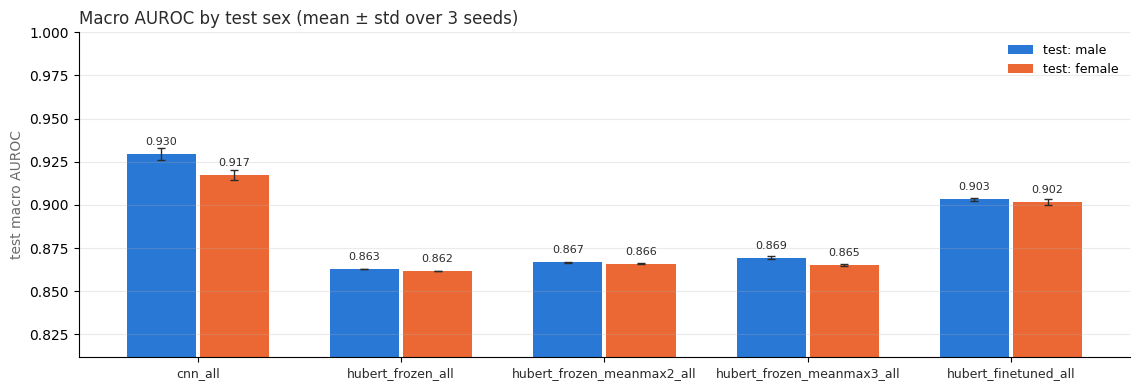

In [ ]:
# Figure: macro AUROC by test sex for each model (mean ± std over seeds)
SEX_COLORS = {"male": "#2a78d6", "female": "#eb6834"}     # categorical slots 1-2, validated for CVD separation
INK, MUTED = "#2b2b2b", "#6b6b6b"

means = summary.xs("mean", axis=1, level=1)
stds = summary.xs("std", axis=1, level=1)
x = np.arange(len(MODEL_ORDER))
w = 0.36
fig, ax = plt.subplots(figsize=(1.9 * len(MODEL_ORDER) + 2, 4))
for k, sex in enumerate(["male", "female"]):
    xs = x + (k - 0.5) * w
    vals, errs = means.loc[MODEL_ORDER, f"auroc_{sex}"], stds.loc[MODEL_ORDER, f"auroc_{sex}"]
    ax.bar(xs, vals, w - 0.02, yerr=errs, color=SEX_COLORS[sex], label=f"test: {sex}",
           error_kw=dict(ecolor=INK, lw=1, capsize=3))
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color=INK)
lo = means.loc[MODEL_ORDER, ["auroc_male", "auroc_female"]].values.min()
ax.set_ylim(max(0.5, lo - 0.05), 1.0)
ax.set_xticks(x, MODEL_ORDER, fontsize=9, color=INK)
ax.set_ylabel("test macro AUROC", color=MUTED)
ax.set_title("Macro AUROC by test sex (mean ± std over 3 seeds)", color=INK, loc="left")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
save_fig("auroc_by_sex_cnn_vs_hubert")
plt.show()

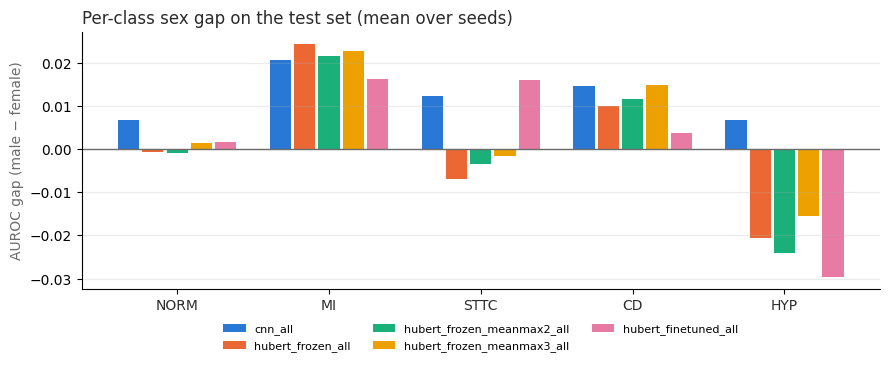

In [ ]:
# Figure: per-class male-female AUROC gap by model (positive = worse on women)
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed categorical order
gap = per_class["gap (M-F)"].unstack(0)[MODEL_ORDER].loc[CLASSES]
x = np.arange(len(CLASSES))
w = 0.8 / len(MODEL_ORDER)
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, m in enumerate(MODEL_ORDER):
    ax.bar(x + (k - (len(MODEL_ORDER) - 1) / 2) * w, gap[m], w - 0.02, color=MODEL_COLORS[k], label=m)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, CLASSES, color=INK)
ax.set_ylabel("AUROC gap (male − female)", color=MUTED)
ax.set_title("Per-class sex gap on the test set (mean over seeds)", color=INK, loc="left")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
save_fig("per_class_gap_cnn_vs_hubert")
plt.show()

### Notes for the Check-in 3 write-up

Fill in after running:
- **Did pretraining help overall?** `hubert_finetuned_all` vs `cnn_all`, test: all / male / female. Is the difference bigger than the seed std (~0.003-0.005 for the CNN)?
- **Frozen vs fine-tuned (the ablation):** how much of the gain needs the encoder to adapt to PTB-XL? A strong frozen probe means the pretrained representation already carries the diagnostic signal.
- **Window pooling:** `frozen` → `frozen_meanmax2` (learned mean + max vs averaging probabilities) and `frozen_meanmax2` → `frozen_meanmax3` (overlapping middle window). Which classes move? Pooling should matter most for findings that don't appear in every beat.
- **Did it shrink the male-female gap?** Compare `gap_auroc (M-F)` and the per-class gaps, especially MI (the gap sex-matching couldn't fix) and HYP (low-voltage female cases).
- **Does the frozen encoder carry the same gap?** It never saw our labels or sex split, so a gap there points to the signal/labels, not the training composition.
- **Miss rates in women:** did MI / STTC / CD miss rates for women drop?
- **Leakage caveat:** PTB-XL (likely including test folds) was in the unlabeled pretraining data.

### Download outputs (Colab)

In [ ]:
if IN_COLAB:
    subprocess.run(["zip", "-qr", "/content/hubert_outputs.zip", "hubert_results", "figures/hubert_figures"],
                   cwd="..", check=True)
    shutil.copy("/content/hubert_outputs.zip", DRIVE_DIR)
    from google.colab import files
    files.download("/content/hubert_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>